# Initial Data Exploration

In [1]:
import pandas as pd
import numpy as np

df_orders = pd.read_csv(
    "../data/raw/olist_orders_dataset.csv",
    dtype={
        "order_id": "string",
        "customer_id": "string",
        "order_status": "string"
    }
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Shape:", df_orders.shape)
print("\nColumns:")
print(df_orders.columns.tolist())

Shape: (99441, 8)

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [3]:
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  string
 1   customer_id                    99441 non-null  string
 2   order_status                   99441 non-null  string
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(5), string(3)
memory usage: 6.1+ MB


In [4]:
display(df_orders.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
display(df_orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [6]:
display(df_orders.describe(include="all").T)

,count,unique,top,freq
order_id,99441,99441,53cdb2fc8bc7dce0b6741e2150273451,1
customer_id,99441,99441,b0830fb4747a6c6d20dea0b8c802d7ef,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:05:26,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-08 19:36:48,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


In [7]:
print("Duplicate rows:", df_orders.duplicated().sum())
print("Duplicate order IDs:", df_orders["order_id"].duplicated().sum())

Duplicate rows: 0
Duplicate order IDs: 0


## Orders Dataset – Initial Exploration

- Total records: 99,441
- Total columns: 8
- Unique order IDs: 99,441
- Unique customer IDs: 99,441
- Unique order statuses: 8
- Missing values: 4,908
- Duplicate order IDs: 0

### Initial Findings
1. Five timestamp columns are stored as object data types.
2. Missing values exist in approval and delivery timestamps.
3. Delivered is the most frequent order status.
4. No duplicate order IDs were identified.

Further investigation is required to understand missing timestamps
and order-status distribution.

In [9]:
status_summary = (
    df_orders["order_status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = ["order_status", "order_count"]

status_summary["percentage"] = (
    status_summary["order_count"] /
    len(df_orders) * 100
).round(2)

display(status_summary)

,order_status,order_count,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.3
6,created,5,0.01
7,approved,2,0.0


### Order Status Distribution – Key Findings

1. Delivered orders account for 97.02% of all records.
2. 625 orders were canceled (0.63%).
3. 609 orders were unavailable (0.61%).
4. 1,107 orders were shipped (1.11%).
5. Only 7 orders are in created or approved status.

Business observation:
The dataset is heavily concentrated around delivered orders.
Canceled and unavailable orders will require further investigation.

In [10]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    df_orders[col] = pd.to_datetime(df_orders[col], errors="coerce")

df_orders[date_columns].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_purchase_timestamp       99441 non-null  datetime64[ns]
 1   order_approved_at              99281 non-null  datetime64[ns]
 2   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 3   order_delivered_customer_date  96476 non-null  datetime64[ns]
 4   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5)
memory usage: 3.8 MB


### Datetime Conversion

Converted all five timestamp columns from object to datetime64[ns].

- order_purchase_timestamp
- order_approved_at
- order_delivered_carrier_date
- order_delivered_customer_date
- order_estimated_delivery_date

All 99,441 purchase timestamps and estimated delivery dates were successfully converted.

No additional missing values were introduced.

In [11]:
missing_analysis = df_orders[
    date_columns + ["order_status"]
].isnull().groupby(df_orders["order_status"]).sum()

display(missing_analysis)

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_status
order_status,,,,,,
approved,0,0,2,2,0,0
canceled,0,141,550,619,0,0
created,0,5,5,5,0,0
delivered,0,14,2,8,0,0
invoiced,0,0,314,314,0,0
processing,0,0,301,301,0,0
shipped,0,0,0,1107,0,0
unavailable,0,0,609,609,0,0


In [12]:
timeline_issues = df_orders[
    (df_orders["order_approved_at"] < df_orders["order_purchase_timestamp"]) |
    (df_orders["order_delivered_carrier_date"] < df_orders["order_approved_at"]) |
    (df_orders["order_delivered_customer_date"] < df_orders["order_delivered_carrier_date"])
]

print("Timeline inconsistencies:", len(timeline_issues))

display(timeline_issues.head(10))

Timeline inconsistencies: 1382


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
15,dcb36b511fcac050b97cd5c05de84dc3,3b6828a50ffe546942b7a473d70ac0fc,delivered,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32,2018-07-04
64,688052146432ef8253587b930b01a06d,81e08b08e5ed4472008030d70327c71f,delivered,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,2018-05-15
199,58d4c4747ee059eeeb865b349b41f53a,1755fad7863475346bc6c3773fe055d3,delivered,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19,2018-07-31
210,412fccb2b44a99b36714bca3fef8ad7b,c6865c523687cb3f235aa599afef1710,delivered,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42,2018-07-31
415,56a4ac10a4a8f2ba7693523bb439eede,78438ba6ace7d2cb023dbbc81b083562,delivered,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39,2018-08-06
481,32e4fa9bb468884309b58b9348de70c3,e54367d4b00c5cb76d2dfe71b9bdb89c,delivered,2018-07-04 16:49:21,2018-07-05 16:33:06,2018-07-05 14:50:00,2018-07-07 14:41:18,2018-07-23
483,4df92d82d79c3b52c7138679fa9b07fc,ba0660bf3fffe505ee892e153a2fbd49,delivered,2018-07-24 11:32:11,2018-07-29 23:30:52,2018-07-26 14:46:00,2018-07-27 18:55:57,2018-08-06
585,16e38caa92e342c7780f68832f832d4d,d29935fdaf4a76f34653da3def4f2a24,delivered,2018-05-07 01:09:09,2018-05-07 16:52:39,2018-05-07 15:09:00,2018-05-24 00:31:18,2018-06-07
615,b9afddbdcfadc9a87b41a83271c3e888,85c6af75161b8b2b1af98e82b5a6a5a5,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,2018-08-24 14:58:37,2018-09-04
817,6051e6d3da9a50b7325cbe9c81025062,c25122206bfcb3ffa950706e1cb10f2b,delivered,2018-07-03 23:40:16,2018-07-05 16:31:26,2018-07-04 12:14:00,2018-07-05 22:52:28,2018-07-19


In [13]:
timeline_checks = {
    "Approval before purchase": (
        df_orders["order_approved_at"] <
        df_orders["order_purchase_timestamp"]
    ),
    "Carrier before approval": (
        df_orders["order_delivered_carrier_date"] <
        df_orders["order_approved_at"]
    ),
    "Customer delivery before carrier": (
        df_orders["order_delivered_customer_date"] <
        df_orders["order_delivered_carrier_date"]
    )
}

for issue, condition in timeline_checks.items():
    print(f"{issue}: {condition.sum()}")

Approval before purchase: 0
Carrier before approval: 1359
Customer delivery before carrier: 23


### Order Timeline Validation

Identified 1,382 chronological inconsistencies.

- Approval before purchase: 0
- Carrier date before approval: 1,359
- Customer delivery before carrier: 23

Decision:
- Original timestamps will be preserved.
- No dates will be manually corrected.
- Inconsistent records will be flagged.
- Delivery performance calculations will account for these inconsistencies.

In [14]:
df_orders_clean = df_orders.copy()

df_orders_clean["timeline_issue"] = (
    (df_orders_clean["order_approved_at"] <
     df_orders_clean["order_purchase_timestamp"]) |
    (df_orders_clean["order_delivered_carrier_date"] <
     df_orders_clean["order_approved_at"]) |
    (df_orders_clean["order_delivered_customer_date"] <
     df_orders_clean["order_delivered_carrier_date"])
)

df_orders_clean.to_csv(
    "../data/processed/orders_clean.csv",
    index=False
)

print("Export completed!")
print("Total records:", len(df_orders_clean))
print("Flagged records:", df_orders_clean["timeline_issue"].sum())

Export completed!
Total records: 99441
Flagged records: 1382


# Order Status Distribution

In [15]:
status_summary = (
    df_orders["order_status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = ["order_status", "order_count"]

status_summary["percentage"] = (
    status_summary["order_count"] /
    len(df_orders) * 100
).round(2)

display(status_summary)

,order_status,order_count,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.3
6,created,5,0.01
7,approved,2,0.0


# Monthly Order Trends
- How does order volume change month by month? Which months have the highest and lowest order activity?

In [16]:
df_orders["order_month"] = (
    df_orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_orders = (
    df_orders.groupby("order_month")
    .size()
    .reset_index(name="total_orders")
)

monthly_orders["order_month"] = (
    monthly_orders["order_month"].astype(str)
)

display(monthly_orders)

,order_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


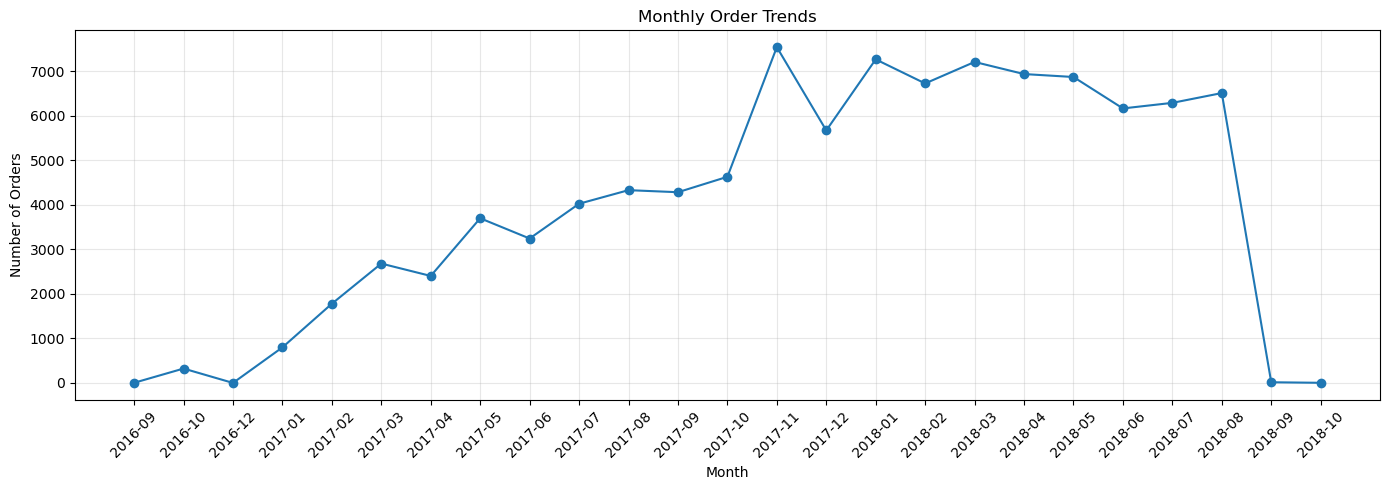

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_orders["order_month"],
    monthly_orders["total_orders"],
    marker="o"
)

plt.title("Monthly Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

In [18]:
highest_month = monthly_orders.loc[
    monthly_orders["total_orders"].idxmax()
]

lowest_month = monthly_orders.loc[
    monthly_orders["total_orders"].idxmin()
]

print("Highest order month:")
print(highest_month)

print("\nLowest order month:")
print(lowest_month)

Highest order month:
order_month     2017-11
total_orders       7544
Name: 13, dtype: object

Lowest order month:
order_month     2016-12
total_orders          1
Name: 2, dtype: object


### Monthly Order Trends – Key Findings

1. November 2017 recorded the highest order volume (7,544).
2. Order volume showed strong growth throughout 2017.
3. Monthly order activity remained relatively stable during 2018.
4. September 2018 recorded only 16 orders.
5. October 2018 recorded only 4 orders.

Business observation:
Order activity increased significantly from 2017 to 2018.
The final months show unusually low activity and should be
treated cautiously due to potentially incomplete data.

# Daily and Weekly Order Trends

In [19]:
df_orders["order_day"] = (
    df_orders["order_purchase_timestamp"].dt.day_name()
)

daily_orders = (
    df_orders["order_day"]
    .value_counts()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
    .reset_index()
)

daily_orders.columns = ["day", "total_orders"]

display(daily_orders)

,day,total_orders
0,Monday,16196
1,Tuesday,15963
2,Wednesday,15552
3,Thursday,14761
4,Friday,14122
5,Saturday,10887
6,Sunday,11960


### Daily Order Trends – Key Findings

1. Monday recorded the highest order volume (16,196).
2. Saturday recorded the lowest order volume (10,887).
3. Weekdays generate considerably more orders than weekends.
4. Order activity gradually declines from Monday to Saturday.

Business observation:
Customer purchasing activity is stronger during weekdays.
This pattern may help businesses plan staffing and order processing capacity.

# Monthly Purchase Patterns

In [20]:
df_orders["month_name"] = (
    df_orders["order_purchase_timestamp"].dt.month_name()
)

monthly_seasonality = (
    df_orders.groupby(
        df_orders["order_purchase_timestamp"].dt.month
    )
    .size()
    .reset_index(name="total_orders")
)

monthly_seasonality["month_name"] = (
    pd.to_datetime(
        monthly_seasonality["order_purchase_timestamp"],
        format="%m"
    ).dt.month_name()
)

display(monthly_seasonality)

,order_purchase_timestamp,total_orders,month_name
0,1,8069,January
1,2,8508,February
2,3,9893,March
3,4,9343,April
4,5,10573,May
5,6,9412,June
6,7,10318,July
7,8,10843,August
8,9,4305,September
9,10,4959,October


### Monthly Purchase Patterns – Key Findings

1. August recorded the highest order volume (10,843).
2. May ranked second with 10,573 orders.
3. July recorded 10,318 orders.
4. September recorded the lowest order volume (4,305).
5. The monthly totals combine data across multiple years.

Business observation:
August, May and July show comparatively higher purchasing activity.
Further year-wise analysis is needed to confirm seasonal patterns.

# Cancellation Analysis

In [21]:
total_orders = len(df_orders)

canceled_orders = (
    df_orders["order_status"] == "canceled"
).sum()

cancellation_rate = (
    canceled_orders / total_orders
) * 100

print("Total Orders:", total_orders)
print("Canceled Orders:", canceled_orders)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Total Orders: 99441
Canceled Orders: 625
Cancellation Rate: 0.63 %


### Cancellation Analysis – Key Findings

1. Total orders: 99,441.
2. Canceled orders: 625.
3. Overall cancellation rate: 0.63%.

Business observation:
The overall cancellation rate is 0.63%.
Monthly analysis can help identify periods with unusually high cancellations.

# Unavailable Orders

In [22]:
unavailable_orders = (
    df_orders["order_status"] == "unavailable"
).sum()

unavailable_rate = (
    unavailable_orders / len(df_orders)
) * 100

print("Total Orders:", len(df_orders))
print("Unavailable Orders:", unavailable_orders)
print("Unavailable Rate:", round(unavailable_rate, 2), "%")

Total Orders: 99441
Unavailable Orders: 609
Unavailable Rate: 0.61 %


### Unavailable Orders – Key Findings

1. Total orders: 99,441.
2. Unavailable orders: 609.
3. Unavailable rate: 0.61%.

Business observation:
Unavailable orders account for 0.61% of total orders.
These orders may indicate inventory or fulfilment issues,
which require further investigation.

# Order Approval Time

In [23]:
df_orders["approval_time_hours"] = (
    df_orders["order_approved_at"] -
    df_orders["order_purchase_timestamp"]
).dt.total_seconds() / 3600

valid_approval = df_orders[
    df_orders["approval_time_hours"].notna() &
    (df_orders["approval_time_hours"] >= 0)
]

print("Valid orders:", len(valid_approval))
print("Average approval time:",
      round(valid_approval["approval_time_hours"].mean(), 2), "hours")
print("Median approval time:",
      round(valid_approval["approval_time_hours"].median(), 2), "hours")

Valid orders: 99281
Average approval time: 10.42 hours
Median approval time: 0.34 hours


### Order Approval Time – Key Findings

1. Valid orders analysed: 99,281.
2. Average approval time: 10.42 hours.
3. Median approval time: 0.34 hours.

Business observation:
Most orders appear to get approved relatively quickly.
However, some orders experience longer approval delays,
increasing the overall average.

# Shipping Time

In [24]:
df_orders["shipping_time_hours"] = (
    df_orders["order_delivered_carrier_date"] -
    df_orders["order_approved_at"]
).dt.total_seconds() / 3600

valid_shipping = df_orders[
    df_orders["shipping_time_hours"].notna() &
    (df_orders["shipping_time_hours"] >= 0)
]

print("Valid orders:", len(valid_shipping))
print(
    "Average shipping time:",
    round(valid_shipping["shipping_time_hours"].mean(), 2),
    "hours"
)
print(
    "Median shipping time:",
    round(valid_shipping["shipping_time_hours"].median(), 2),
    "hours"
)

Valid orders: 96285
Average shipping time: 68.62 hours
Median shipping time: 44.44 hours


### Shipping Time – Key Findings

1. Valid orders analysed: 96,285.
2. Average shipping time: 68.62 hours (2.86 days).
3. Median shipping time: 44.44 hours (1.85 days).

Business observation:
Most orders reach the carrier within approximately two days.
Some orders experience longer processing or dispatch times,
increasing the overall average.

# Customer Delivery Time

In [25]:
df_orders["delivery_time_days"] = (
    df_orders["order_delivered_customer_date"] -
    df_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

valid_delivery = df_orders[
    df_orders["delivery_time_days"].notna() &
    (df_orders["delivery_time_days"] >= 0)
]

print("Valid orders:", len(valid_delivery))

print(
    "Average delivery time:",
    round(valid_delivery["delivery_time_days"].mean(), 2),
    "days"
)

print(
    "Median delivery time:",
    round(valid_delivery["delivery_time_days"].median(), 2),
    "days"
)

Valid orders: 96476
Average delivery time: 12.56 days
Median delivery time: 10.22 days


### Customer Delivery Time – Key Findings

1. Valid orders analysed: 96,476.
2. Average delivery time: 12.56 days.
3. Median delivery time: 10.22 days.

Business observation:
Customers receive their orders in approximately 12.56 days on average.
Some orders take considerably longer, increasing the average delivery time.

# Estimated vs Actual Delivery

In [26]:
df_orders["delivery_difference_days"] = (
    df_orders["order_delivered_customer_date"] -
    df_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

valid_estimates = df_orders[
    df_orders["order_delivered_customer_date"].notna()
].copy()

valid_estimates["delivery_result"] = np.where(
    valid_estimates["delivery_difference_days"] < 0,
    "Early",
    np.where(
        valid_estimates["delivery_difference_days"] > 0,
        "Late",
        "On Time"
    )
)

print(valid_estimates["delivery_result"].value_counts())

delivery_result
Early    88649
Late      7827
Name: count, dtype: int64


In [27]:
delivery_summary = (
    valid_estimates["delivery_result"]
    .value_counts()
    .reset_index()
)

delivery_summary.columns = ["delivery_result", "orders"]

delivery_summary["percentage"] = (
    delivery_summary["orders"] /
    len(valid_estimates) * 100
).round(2)

display(delivery_summary)

,delivery_result,orders,percentage
0,Early,88649,91.89
1,Late,7827,8.11


### Estimated vs Actual Delivery – Key Findings

1. Early deliveries: 88,649 (91.89%).
2. Late deliveries: 7,827 (8.11%).
3. On-time deliveries: 0 (0%).

Business observation:
Most delivered orders arrived before their estimated delivery dates.
However, 8.11% experienced late delivery, indicating opportunities
to improve fulfilment and logistics performance.

# Late Delivery Analysis

In [28]:
late_orders = valid_estimates[
    valid_estimates["delivery_difference_days"] > 0
]

print("Late orders:", len(late_orders))

print(
    "Average delay:",
    round(late_orders["delivery_difference_days"].mean(), 2),
    "days"
)

print(
    "Median delay:",
    round(late_orders["delivery_difference_days"].median(), 2),
    "days"
)

print(
    "Maximum delay:",
    round(late_orders["delivery_difference_days"].max(), 2),
    "days"
)

Late orders: 7827
Average delay: 9.55 days
Median delay: 5.81 days
Maximum delay: 188.98 days


### Late Delivery Analysis – Key Findings

1. Late orders: 7,827.
2. Average delivery delay: 9.55 days.
3. Median delivery delay: 5.81 days.
4. Maximum delivery delay: 188.98 days.

Business observation:
Most late orders experience delays of several days.
A few extreme delays significantly affect overall delivery performance.
These outliers require further investigation.

# Customer Purchase Frequency

In [29]:
customer_orders = (
    df_orders.groupby("customer_id")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

frequency_summary = (
    customer_orders["total_orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

frequency_summary.columns = [
    "order_frequency",
    "customer_count"
]

frequency_summary["percentage"] = (
    frequency_summary["customer_count"] /
    len(customer_orders) * 100
).round(2)

display(frequency_summary)

print("Total unique customers:", len(customer_orders))
print(
    "Repeat customers:",
    (customer_orders["total_orders"] > 1).sum()
)

,order_frequency,customer_count,percentage
0,1,99441,100.0


Total unique customers: 99441
Repeat customers: 0


- Repeat customers: 0 is not necessarily the actual business finding. The problem is that customer_id in the Olist dataset is unique for each order, so grouping by it cannot identify returning customers.

- We need to use customer_unique_id from the Customers dataset.

In [30]:
df_customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv",
    dtype={
        "customer_id": "string",
        "customer_unique_id": "string"
    }
)

In [31]:
orders_customers = df_orders.merge(
    df_customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

customer_orders = (
    orders_customers.groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

frequency_summary = (
    customer_orders["total_orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

frequency_summary.columns = [
    "order_frequency",
    "customer_count"
]

frequency_summary["percentage"] = (
    frequency_summary["customer_count"] /
    len(customer_orders) * 100
).round(2)

display(frequency_summary)

print("Unique customers:", len(customer_orders))
print(
    "Repeat customers:",
    (customer_orders["total_orders"] > 1).sum()
)

,order_frequency,customer_count,percentage
0,1,93099,96.88
1,2,2745,2.86
2,3,203,0.21
3,4,30,0.03
4,5,8,0.01
5,6,6,0.01
6,7,3,0.00
7,9,1,0.00
8,17,1,0.00


Unique customers: 96096
Repeat customers: 2997


### Customer Purchase Frequency – Key Findings

1. Unique customers: 96,096.
2. One-time customers: 93,099 (96.88%).
3. Repeat customers: 2,997 (3.12%).
4. Highest observed order frequency: 17 orders.

Business observation:
The majority of customers made only one purchase.
The low repeat-purchase rate indicates an opportunity
to improve customer retention and loyalty.